## Dry Bean Classification

I chose the UCI Dry Bean dataset for this assignment. It contains
13,611 records, 16 numerical features and seven bean varieties. The
features describe measurements such as area, perimeter and shape.
The aim is to predict the bean variety from these measurements.

I will compare the following models using the same training and test split:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine

Before training, I will check the data for missing values and duplicate
records. Any scaling or other preprocessing will be fitted using only
the training data.

I will compare the models using Accuracy, AUC, Precision, Recall,
F1 Score and MCC. Since this is a multiclass problem, I will use macro
averages for Precision, Recall and F1, and macro one-vs-rest AUC.

Finally, I will save the trained models with their preprocessing steps
so they can be used in the Streamlit app.

**Dataset source:**  
https://archive.ics.uci.edu/dataset/602/dry+bean+dataset

**Official source:** https://archive.ics.uci.edu/dataset/602/dry+bean+dataset  
**Official download:** https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip  
**Dataset DOI:** https://doi.org/10.24432/C50S4B

The target is bean variety (`Class`). The inputs are 16 numerical shape and
size measurements extracted from bean images, not raw images.
The seven labels are `BARBUNYA`, `BOMBAY`, `CALI`, `DERMASON`, `HOROZ`,
`SEKER` and `SIRA`. The input file preserves UCI's original spellings,
including `AspectRation` and lowercase `roundness`.

The raw dataset has 13,611 rows and 68 exact duplicate rows. This notebook
removes those duplicates **before splitting** so the same measured example
cannot occur in both training and test partitions. The resulting 13,543
unique rows still satisfy the assignment minimums.

## 2. Dataset Description

The Dry Bean dataset contains measurements taken from images of seven
bean varieties. The task is to predict the variety, given in the `Class`
column, using 16 numerical features.

These features describe the size and shape of each bean, including its
area, perimeter, axis lengths, roundness and compactness. The dataset
contains measurements rather than the original images.

The seven classes are:
- BARBUNYA
- BOMBAY
- CALI
- DERMASON
- HOROZ
- SEKER
- SIRA

This dataset meets the assignment requirements, with 13,611 records and
16 input features. It also provides a multiclass classification problem
for comparing the five required models.

The data check identified 68 exact duplicate rows. I will remove these
before creating the training and test sets to prevent identical records
from appearing in both. This leaves 13,543 records for the analysis.

I will keep the original column names, including `AspectRation` and
`roundness`, consistent throughout the notebook and app.

**Dataset source:**  
https://archive.ics.uci.edu/dataset/602/dry+bean+dataset

**Download link:**  
https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip

**Dataset DOI:**  
https://doi.org/10.24432/C50S4B


In [3]:
%pip install scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


In [4]:
import importlib.metadata
from pathlib import Path
from urllib.request import urlopen
from io import BytesIO
import hashlib
import json
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay,
    f1_score, matthews_corrcoef, precision_score, recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    cross_validate, StratifiedKFold, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# These are exercise building blocks, not fitted assignment models.
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
TEST_FRACTION = 0.20

packages = ["numpy", "pandas", "scikit-learn", "matplotlib", "openpyxl", "joblib"]
versions = {name: importlib.metadata.version(name) for name in packages}
display(pd.Series(versions, name="Installed version").to_frame())
print("Working directory:", BASE_DIR)
print("Demonstration seed:", RANDOM_STATE, "| Held-out fraction:", TEST_FRACTION)

,Installed version
numpy,2.5.4
pandas,2.2.3
scikit-learn,1.9.1
matplotlib,3.10.1
openpyxl,3.1.5
joblib,1.4.2


Working directory: /home/s2026ak05717/Desktop/ML/Assignment 2
Demonstration seed: 42 | Held-out fraction: 0.2


## 4. Load the official data and inspect its quality

The archive is cached locally. Its SHA-256 digest is checked against the
official archive downloaded when this notebook was prepared. If UCI changes
the archive, investigate that change rather than silently accepting a
different file. No archive paths are extracted into the filesystem; only
the named spreadsheet is read into memory.

In [10]:
DATA_URL = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
EXPECTED_SHA256 = "0a64eff5be87f48c3dbbfc0a12a56c5d5b5167ef8e61cd45d69b3e7c7130c06f"
archive_path = DATA_DIR / "dry_bean_uci.zip"

if not archive_path.exists():
    print("Downloading the public UCI archive...")
    with urlopen(DATA_URL, timeout=90) as response:
        archive_bytes = response.read()
    digest = hashlib.sha256(archive_bytes).hexdigest()
    if digest != EXPECTED_SHA256:
        raise ValueError("UCI archive checksum changed; review its provenance.")
    archive_path.write_bytes(archive_bytes)
else:
    archive_bytes = archive_path.read_bytes()

actual_digest = hashlib.sha256(archive_bytes).hexdigest()
if actual_digest != EXPECTED_SHA256:
    raise ValueError("Cached archive does not match the reviewed UCI archive.")

with zipfile.ZipFile(BytesIO(archive_bytes)) as archive:
    spreadsheet = archive.read("DryBeanDataset/Dry_Bean_Dataset.xlsx")
raw_data = pd.read_excel(BytesIO(spreadsheet), engine="openpyxl")

TARGET = "Class"
FEATURE_COLUMNS = [
    "Area", "Perimeter", "MajorAxisLength", "MinorAxisLength",
    "AspectRation", "Eccentricity", "ConvexArea", "EquivDiameter",
    "Extent", "Solidity", "roundness", "Compactness",
    "ShapeFactor1", "ShapeFactor2", "ShapeFactor3", "ShapeFactor4",
]
if list(raw_data.columns) != FEATURE_COLUMNS + [TARGET]:
    raise ValueError("Unexpected columns or column order in the UCI spreadsheet.")
if raw_data.shape != (13611, 17):
    raise ValueError("Unexpected raw dataset dimensions.")
if not all(pd.api.types.is_numeric_dtype(raw_data[c]) for c in FEATURE_COLUMNS):
    raise TypeError("All input features must be numerical.")
if raw_data[TARGET].isna().any():
    raise ValueError("A missing target label must be investigated.")
if not np.isfinite(raw_data[FEATURE_COLUMNS].to_numpy(dtype=float)).all():
    raise ValueError("Unexpected missing or infinite feature values.")

print("Source:", DATA_URL)
print("SHA-256:", actual_digest)
print("Raw rows:", len(raw_data), "| Features:", len(FEATURE_COLUMNS))
print("Classes:", sorted(raw_data[TARGET].unique()))
print("Missing values:", int(raw_data.isna().sum().sum()))
print("Exact duplicate rows:", int(raw_data.duplicated().sum()))
display(raw_data.head())

Source: https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip
SHA-256: 0a64eff5be87f48c3dbbfc0a12a56c5d5b5167ef8e61cd45d69b3e7c7130c06f
Raw rows: 13611 | Features: 16
Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Missing values: 0
Exact duplicate rows: 68


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [12]:
# Duplicate measurements with contradictory labels require investigation.
conflicting_groups = (
    raw_data.groupby(FEATURE_COLUMNS, dropna=False)[TARGET].nunique().gt(1)
)
if conflicting_groups.any():
    raise ValueError("Identical feature vectors have contradictory target labels.")

data = raw_data.drop_duplicates().reset_index(drop=True)
assert data.shape == (13543, 17)
assert len(FEATURE_COLUMNS) >= 12 and len(data) >= 500
print("Rows after removing exact duplicates:", len(data))
display(data[FEATURE_COLUMNS].describe().T.round(4))

Rows after removing exact duplicates: 13543


,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.4604,29392.4383,20420.0000,36282.5000,44580.0000,61382.0000,254616.0000
Perimeter,13543.0,854.9934,214.7227,524.7360,703.2300,793.8960,977.1465,1985.3700
MajorAxisLength,13543.0,319.8956,85.8093,183.6012,253.0868,296.4046,376.3125,738.8602
MinorAxisLength,13543.0,202.3653,45.0516,122.5127,175.8864,192.4911,217.2454,460.1985
AspectRation,13543.0,1.5811,0.2452,1.0249,1.4307,1.5499,1.7039,2.4303
Eccentricity,13543.0,0.7503,0.0919,0.2190,0.7151,0.7640,0.8097,0.9114
ConvexArea,13543.0,53767.9867,29844.2485,20684.0000,36673.0000,45122.0000,62360.0000,263261.0000
EquivDiameter,13543.0,253.0341,59.3077,161.2438,214.9333,238.2457,279.5604,569.3744
Extent,13543.0,0.7498,0.0489,0.5553,0.7187,0.7599,0.7868,0.8662
Solidity,13543.0,0.9872,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947


## 5. Create one leakage-safe train/test split

Stratification preserves representation of all seven classes. Do not fit
the imputer or scaler before this split. Each model will own its preprocessing
inside a scikit-learn `Pipeline`, fitted on training data only.

The held-out test partition is for the final comparison, not for tuning
hyperparameters. Use training-only cross-validation for selection. This
does not prove that the original image measurements are statistically
independent; the duplicate check addresses only exact duplicates.

In [15]:
X = data[FEATURE_COLUMNS]
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_FRACTION, stratify=y, random_state=RANDOM_STATE
)
CLASS_LABELS = np.array(sorted(y.unique()))

assert X_train.index.intersection(X_test.index).empty
assert set(y_train.unique()) == set(CLASS_LABELS)
assert set(y_test.unique()) == set(CLASS_LABELS)
assert TARGET not in X_train.columns

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
class_counts = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Held-out test": y_test.value_counts(),
}).reindex(CLASS_LABELS)
display(class_counts)

# Only held-out rows, with all features and the target, go in this upload file.
test_csv = X_test.copy()
test_csv[TARGET] = y_test
test_csv.to_csv(BASE_DIR / "test_data.csv", index=False)
print("Created test_data.csv:", test_csv.shape)

Training shape: (10834, 16)
Test shape: (2709, 16)


,Training,Held-out test
Class,,
BARBUNYA,1057,265
BOMBAY,418,104
CALI,1304,326
DERMASON,2837,709
HOROZ,1488,372
SEKER,1621,406
SIRA,2109,527


Created test_data.csv: (2709, 17)


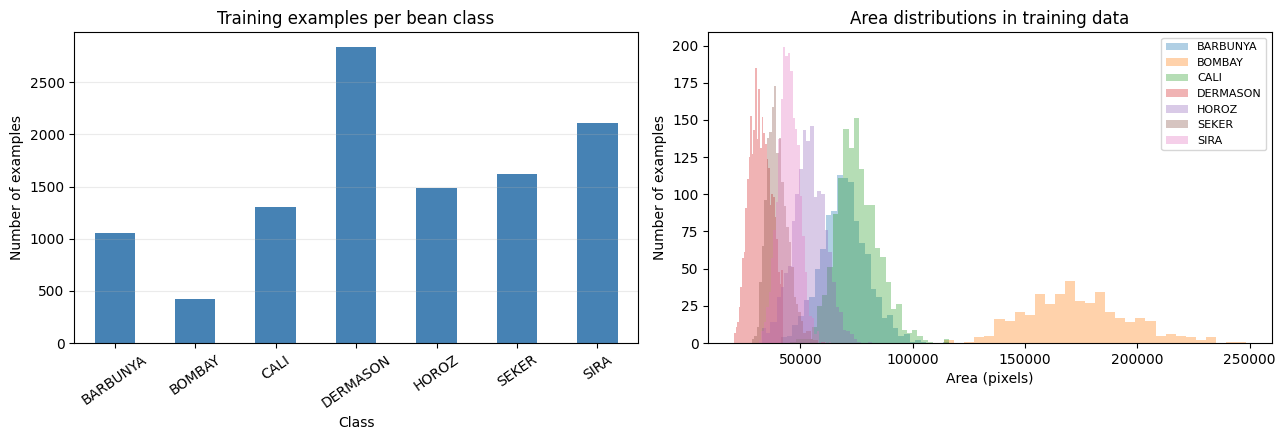

Training majority-class share: 0.2619
This is descriptive context, not a result for any required model.


In [17]:
# Descriptive visualizations use the training partition.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
y_train.value_counts().reindex(CLASS_LABELS).plot.bar(
    ax=axes[0], color="steelblue", rot=35
)
axes[0].set(title="Training examples per bean class",
            xlabel="Class", ylabel="Number of examples")
axes[0].grid(axis="y", alpha=0.25)
for label in CLASS_LABELS:
    values = X_train.loc[y_train == label, "Area"]
    axes[1].hist(values, bins=30, alpha=0.35, label=label)
axes[1].set(title="Area distributions in training data",
            xlabel="Area (pixels)", ylabel="Number of examples")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

majority_share = y_train.value_counts(normalize=True).max()
print(f"Training majority-class share: {majority_share:.4f}")
print("This is descriptive context, not a result for any required model.")

## 6. Preprocessing example

Median imputation is included as a deployable precaution, although the
reviewed UCI dataset has no missing feature values. It is learned on the
training data inside the pipeline.

Standardization is generally important for Logistic Regression, KNN and
SVM because these features have very different units and ranges.
Decision trees do not require scaling. Gaussian Naive Bayes can operate
without scaling; explain your choice rather than scaling indiscriminately.

In [20]:
def make_preprocessing(scale):
    # This helper is unfitted: fitting occurs only inside each model pipeline.
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    return Pipeline(steps)

## 7. EXERCISES: implement the five required classifiers

Complete each function using the imported estimator and `Pipeline`.
Return an **unfitted** pipeline with two named steps: `"preprocess"` and
`"classifier"`. Use `make_preprocessing(scale=...)` for the first step.
Use scikit-learn estimators; the question sheet does not require
implementing their training algorithms from first principles.

### 7.1 Logistic Regression
I will use Logistic Regression as a baseline for comparing the other
classifiers. It uses a linear decision boundary, so it may struggle to
separate bean varieties whose measurements have more complex relationships.

The features have different scales, so I will standardize them within the
pipeline. The scaler will be fitted only on the training data.

The parameter `C` controls the regularization strength: a smaller value
applies stronger regularization. I will choose this value using training-only
validation. I will also set `max_iter` high enough for the model to converge
and check for convergence warnings during training. 


In [77]:
def build_logistic_regression():
    # Keep preprocessing inside the pipeline to avoid data leakage.
    return Pipeline([
        ("preprocess", make_preprocessing(scale=True)),
        ("classifier", LogisticRegression(
            C=1.0,
            solver="lbfgs",
            max_iter=2000,
        )),
    ])

### 7.2 Decision Tree Classifier

I will use a Decision Tree to classify the bean varieties by splitting
the data using feature thresholds. Unlike Logistic Regression, it can
capture nonlinear relationships without requiring feature scaling.

A very deep tree can fit the training data closely but may overfit.
Limiting `max_depth` or increasing `min_samples_leaf` can reduce this
risk. However, too much restriction can cause underfitting. A smaller
tree is also easier to interpret.

I will use a fixed `random_state` for reproducibility and compare these
parameter choices using training-only validation. This will help me
choose a balance between model complexity and validation performance.


In [80]:
def build_decision_tree():
    # Trees use feature thresholds, so scaling is not required.
    return Pipeline([
        ("preprocess", make_preprocessing(scale=False)),
        ("classifier", DecisionTreeClassifier(
            max_depth=10,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
        )),
    ])

### 7.3 K-Nearest Neighbor Classifier

K-Nearest Neighbors predicts a bean's variety using the classes of nearby
training examples. Since it relies on distances, the scale of the features
is important.

For example, `Area` has much larger numerical values than the shape
factors. Without scaling, it could dominate the distance calculation.
I will standardize the features within the pipeline using only the
training data.

I will compare the number of neighbors, distance metric and weighting
rule using training-only validation. A small neighbor count can be
sensitive to noise, while a large count may overlook local differences
between classes.

KNN stores the training examples rather than learning a compact set of
model parameters, so prediction can become slower as the dataset grows.

In [83]:
def build_knn():
    # Scale the features so large-valued measurements do not dominate.
    return Pipeline([
        ("preprocess", make_preprocessing(scale=True)),
        ("classifier", KNeighborsClassifier(
            n_neighbors=7,
            weights="distance",
            metric="euclidean",
        )),
    ])

### 7.4 Gaussian Naive Bayes

I will use Gaussian Naive Bayes because the inputs are continuous
measurements rather than counts. The model assumes that each feature
follows a Gaussian distribution within each bean class.

It also assumes that the features are independent of one another once
the class is known. Measurements such as area, perimeter and axis lengths
may be related, so this assumption may not hold fully for this dataset.

I will examine feature correlations using the training data. Correlated
features can cause the model to count related information more than once,
which may make its predicted probabilities overconfident. However, the
model can still give useful classification results even when its
assumptions are not fully satisfied.

In [86]:
def build_naive_bayes():
    # Gaussian Naive Bayes models continuous features within each class.
    return Pipeline([
        ("preprocess", make_preprocessing(scale=False)),
        ("classifier", GaussianNB(
            var_smoothing=1e-9,
        )),
    ])

### 7.5 Support Vector Machine

I will use a Support Vector Machine to separate the bean classes.
Feature scaling is important for this model, so I will standardize the
measurements within the pipeline using only the training data.

The kernel determines the type of decision boundary. A linear kernel
produces linear boundaries, while an RBF kernel can capture more complex
relationships. I will compare suitable settings using training-only
validation.

The parameter `C` controls the balance between a wider margin and
penalizing training errors. A larger value penalizes errors more strongly
and may lead to overfitting. For the RBF kernel, `gamma` controls how
locally each training example influences the boundary.

I will set `probability=True` so the model provides the class probabilities
needed to calculate multiclass AUC. This adds to the training time.
Evaluation will use predictions and probabilities from the fitted model
on the held-out test data.

In [89]:
def build_svm():
    # Scale features and enable probabilities for multiclass AUC.
    return Pipeline([
        ("preprocess", make_preprocessing(scale=True)),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            probability=True,
            random_state=RANDOM_STATE,
        )),
    ])

## 8. Set Up the Models for Comparison

I will keep the five model-building functions in one dictionary so that
each model can be trained and evaluated using the same workflow.

Each function should return an unfitted pipeline containing the
preprocessing steps and classifier. Before training, I will check that
all five functions are complete and that each pipeline supports
`predict_proba` for the AUC calculation.

The `IMPLEMENTATION_COMPLETE` flag remains `False` until these checks
are complete. I will then set it to `True`, restart the kernel and run
the notebook from the beginning.


In [92]:
# Use the same validation and evaluation workflow for all five models.
MODEL_BUILDERS = {
    "Logistic Regression": build_logistic_regression,
    "Decision Tree": build_decision_tree,
    "KNN": build_knn,
    "Naive Bayes": build_naive_bayes,
    "Support Vector Machine": build_svm,
}

# Change to True once all five model-building functions are complete.
IMPLEMENTATION_COMPLETE = True

if IMPLEMENTATION_COMPLETE:
    candidate_models = {
        name: build() for name, build in MODEL_BUILDERS.items()
    }

    for name, model in candidate_models.items():
        if not isinstance(model, Pipeline):
            raise TypeError(f"{name} must return a Pipeline.")

        if list(model.named_steps) != ["preprocess", "classifier"]:
            raise ValueError(
                f"{name}: the pipeline must contain 'preprocess' "
                "followed by 'classifier'."
            )

        if not hasattr(model, "predict_proba"):
            raise TypeError(
                f"{name} must support predict_proba for multiclass AUC."
            )

        print(f"{name}: pipeline checks passed.")

    print("\nAll five pipelines are ready for training-only validation.")
else:
    print("Training has not started. The model implementations are still pending.")


Logistic Regression: pipeline checks passed.
Decision Tree: pipeline checks passed.
KNN: pipeline checks passed.
Naive Bayes: pipeline checks passed.
Support Vector Machine: pipeline checks passed.

All five pipelines are ready for training-only validation.


## 9. Training-Only Validation

I will use macro F1 as the main comparison metric because the bean
classes have different numbers of examples. Macro F1 gives each class
equal weight, so performance on the larger classes does not dominate
the comparison.

I will use stratified three-fold cross-validation on the training data.
Each fold keeps approximately the same class proportions. The pipeline
fits its preprocessing and classifier using only that fold's training
portion, then evaluates them on the validation portion.

I will compare the mean macro F1 across the three folds and its standard
deviation to understand how consistent the results are. I will also
record the mean accuracy.

Any parameter changes will be assessed using this training-only
validation. Once the settings are finalized, I will evaluate the models
on the held-out test set without using those results for further tuning

In [95]:
RUN_CROSS_VALIDATION = True

if IMPLEMENTATION_COMPLETE and RUN_CROSS_VALIDATION:
    # Use the same stratified folds for every model.
    folds = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    validation_rows = []

    for name, candidate in candidate_models.items():
        print(f"Running cross-validation: {name}", flush=True)

        # Fit preprocessing and the classifier separately within each fold.
        scores = cross_validate(
            clone(candidate),
            X_train,
            y_train,
            cv=folds,
            scoring={
                "macro_f1": "f1_macro",
                "accuracy": "accuracy",
            },
            n_jobs=1,
            error_score="raise",
        )

        # Summarize performance across the three validation folds.
        validation_rows.append({
            "ML Model Name": name,
            "CV macro F1 mean": scores["test_macro_f1"].mean(),
            "CV macro F1 std": scores["test_macro_f1"].std(ddof=1),
            "CV accuracy mean": scores["test_accuracy"].mean(),
        })

        print(f"Completed: {name}", flush=True)

    validation_table = pd.DataFrame(validation_rows).set_index(
        "ML Model Name"
    )

    print("\nTraining cross-validation results:")
    display(validation_table.round(4))

else:
    print(
        "Cross-validation has not started. Complete the model setup "
        "and enable RUN_CROSS_VALIDATION."
    )

Running cross-validation: Logistic Regression
Completed: Logistic Regression
Running cross-validation: Decision Tree
Completed: Decision Tree
Running cross-validation: KNN
Completed: KNN
Running cross-validation: Naive Bayes
Completed: Naive Bayes
Running cross-validation: Support Vector Machine


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Completed: Support Vector Machine

Training cross-validation results:


,CV macro F1 mean,CV macro F1 std,CV accuracy mean
ML Model Name,,,
Logistic Regression,0.9365,0.0018,0.9244
Decision Tree,0.9178,0.0027,0.9042
KNN,0.9356,0.0000,0.9225
Naive Bayes,0.7634,0.0009,0.7618
Support Vector Machine,0.9410,0.0032,0.9295


## 10. Multiclass Evaluation

I will evaluate all five models on the same held-out test data using
the following six metrics:

- **Accuracy:** the proportion of correctly classified beans.
- **AUC:** macro-averaged one-vs-rest ROC AUC, calculated from predicted
  class probabilities.
- **Precision:** how often predictions for each class are correct.
- **Recall:** how many examples of each class are correctly identified.
- **F1 Score:** the balance between precision and recall for each class.
- **MCC:** a measure of agreement between actual and predicted labels
  that also accounts for classification errors.

I will use macro averaging for Precision, Recall and F1 so that each
of the seven bean classes contributes equally. The same metric
definitions will be used in the notebook, README and Streamlit app.

For AUC, I will use probabilities rather than predicted class labels.
The probability columns must follow the fitted model's `classes_` order
so that each probability is matched to the correct class.

The held-out test set contains all seven classes. If an uploaded test
CSV is missing a class, the app will show the full seven-class macro
AUC as unavailable rather than reporting it as zero.

For Precision, Recall and F1, I will use `zero_division=0` to assign
zero where a class-level calculation is undefined, such as precision
when a class has no predicted examples.


In [98]:
def evaluate_classifier(fitted_model, features, actual_labels):
    # Use the fitted pipeline without retraining.
    predicted_labels = fitted_model.predict(features)
    probabilities = fitted_model.predict_proba(features)

    model_labels = np.asarray(fitted_model.classes_)
    actual_labels = np.asarray(actual_labels)

    # Check that the model and test labels match the expected classes.
    if set(model_labels) != set(CLASS_LABELS):
        raise ValueError("The model must be trained on all seven bean classes.")

    if not set(actual_labels).issubset(set(model_labels)):
        raise ValueError("The test data contains an unknown bean class.")

    # Check the probability output before calculating AUC.
    expected_shape = (len(actual_labels), len(model_labels))
    if probabilities.shape != expected_shape:
        raise ValueError("Probability dimensions do not match the test data.")

    if not np.isfinite(probabilities).all():
        raise ValueError("Predicted probabilities contain missing or infinite values.")

    if (probabilities < 0).any() or (probabilities > 1).any():
        raise ValueError("Predicted probabilities must be between 0 and 1.")

    if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-6):
        raise ValueError("Class probabilities for each row must sum to 1.")

    # Full seven-class AUC requires every class in the test data.
    if set(actual_labels) == set(model_labels):
        auc = roc_auc_score(
            actual_labels,
            probabilities,
            labels=model_labels,
            multi_class="ovr",
            average="macro",
        )
        auc_note = "Macro one-vs-rest AUC calculated for all seven classes."
    else:
        auc = np.nan
        auc_note = "AUC unavailable: the test data does not contain all seven classes."

    # Give each class equal weight in Precision, Recall and F1.
    averaging = {
        "labels": CLASS_LABELS,
        "average": "macro",
        "zero_division": 0,
    }

    metrics = {
        "Accuracy": accuracy_score(actual_labels, predicted_labels),
        "AUC": auc,
        "Precision": precision_score(
            actual_labels, predicted_labels, **averaging
        ),
        "Recall": recall_score(
            actual_labels, predicted_labels, **averaging
        ),
        "F1": f1_score(
            actual_labels, predicted_labels, **averaging
        ),
        "MCC": matthews_corrcoef(actual_labels, predicted_labels),
    }

    return metrics, predicted_labels, auc_note

## 11. Final Training and Model Comparison

After finalizing the model settings using training-only cross-validation,
I will fit each model on the full training partition and evaluate it on
the same held-out test data.

The comparison table will report Accuracy, AUC, Precision, Recall, F1
and MCC for all five models. Macro F1 will remain the primary comparison
metric, supported by the other scores.

I will enable `READY_FOR_FINAL_TEST` only after completing the
implementation and validation decisions. The held-out results will be
used for the final assessment, not for further parameter tuning.


In [103]:
# Change to True after finalizing all training-only validation decisions.
READY_FOR_FINAL_TEST = True

METRIC_COLUMNS = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]

if IMPLEMENTATION_COMPLETE and READY_FOR_FINAL_TEST:
    fitted_models = {}
    predictions = {}
    metric_rows = []

    for name, candidate in candidate_models.items():
        print(f"Training and evaluating: {name}", flush=True)

        # Fit a fresh pipeline on the full training partition.
        fitted = clone(candidate).fit(X_train, y_train)

        # Evaluate every model on the same held-out test rows.
        metrics, predicted, auc_note = evaluate_classifier(
            fitted, X_test, y_test
        )

        # Keep fitted pipelines and predictions for reports and export.
        fitted_models[name] = fitted
        predictions[name] = predicted
        metric_rows.append({"ML Model Name": name, **metrics})

        print(f"{name}: {auc_note}", flush=True)

    comparison_table = pd.DataFrame(metric_rows).set_index("ML Model Name")

    # Round only the display; preserve full precision in the table.
    display(comparison_table[METRIC_COLUMNS].round(4))
    print("Final held-out evaluation completed for all five models.")

else:
    pending_table = pd.DataFrame(
        "PENDING",
        index=pd.Index(MODEL_BUILDERS, name="ML Model Name"),
        columns=METRIC_COLUMNS,
    )
    display(pending_table)
    print(
        "Final evaluation has not run. Complete the model implementations "
        "and finalize training-only validation before enabling the test flag."
    )

Training and evaluating: Logistic Regression
Logistic Regression: Macro one-vs-rest AUC calculated for all seven classes.
Training and evaluating: Decision Tree
Decision Tree: Macro one-vs-rest AUC calculated for all seven classes.
Training and evaluating: KNN
KNN: Macro one-vs-rest AUC calculated for all seven classes.
Training and evaluating: Naive Bayes
Naive Bayes: Macro one-vs-rest AUC calculated for all seven classes.
Training and evaluating: Support Vector Machine


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine: Macro one-vs-rest AUC calculated for all seven classes.


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9192,0.9947,0.9307,0.9300,0.9302,0.9023
Decision Tree,0.9011,0.9703,0.9160,0.9152,0.9155,0.8804
KNN,0.9136,0.9854,0.9268,0.9237,0.9250,0.8956
Naive Bayes,0.7630,0.9670,0.7736,0.7685,0.7669,0.7143
Support Vector Machine,0.9210,0.9945,0.9342,0.9317,0.9328,0.9045


Final held-out evaluation completed for all five models.


## 12. Confusion Matrices and Per-Class Reports

I will inspect the confusion matrices to identify which bean varieties
each model classifies correctly and which varieties it confuses.

Rows represent the actual classes, and columns represent the predicted
classes. Each row is normalized by the number of test examples in that
class, allowing comparison across classes of different sizes. Diagonal
values show the proportion correctly classified, while off-diagonal
values show misclassifications.

The classification reports will show precision, recall, F1 score and
support for each bean class. Support is the number of actual test
examples in that class. These results will help identify class-level
weaknesses that the overall scores may hide.


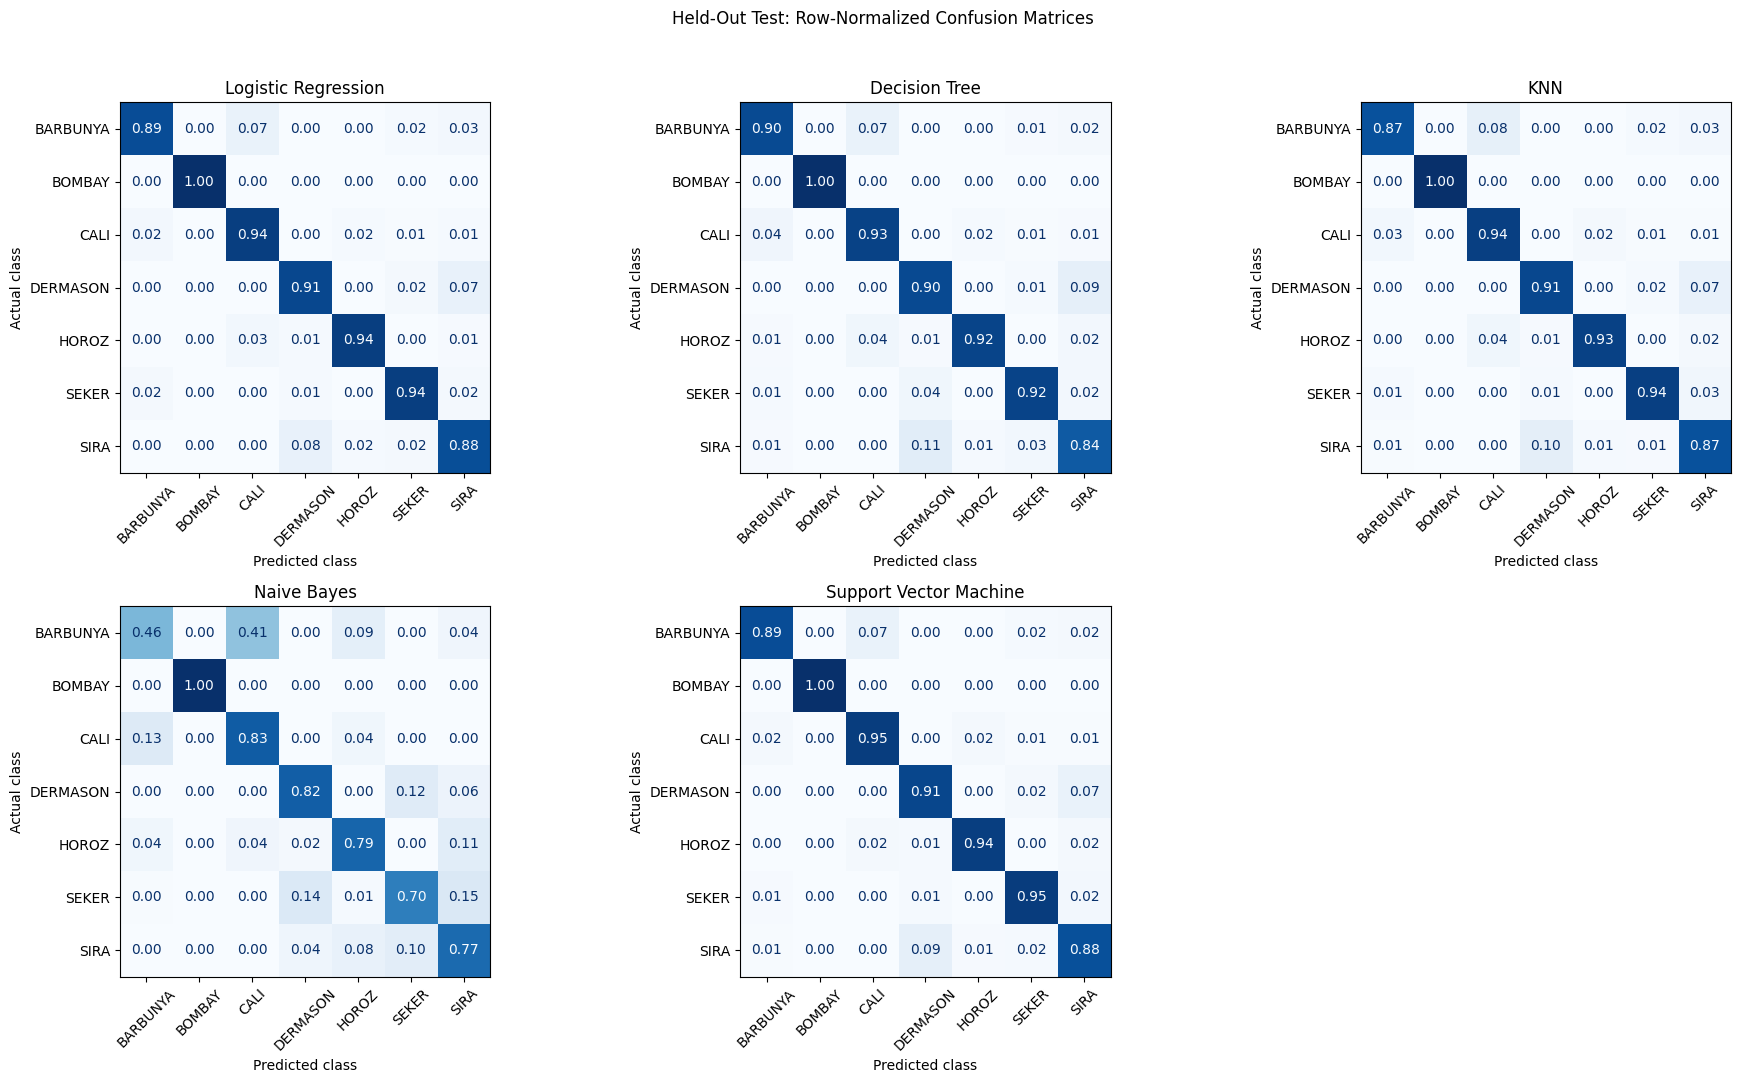


Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA     0.9255    0.8906    0.9077       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9110    0.9417    0.9261       326
    DERMASON     0.9265    0.9069    0.9166       709
       HOROZ     0.9643    0.9435    0.9538       372
       SEKER     0.9296    0.9433    0.9364       406
        SIRA     0.8582    0.8843    0.8710       527

    accuracy                         0.9192      2709
   macro avg     0.9307    0.9300    0.9302      2709
weighted avg     0.9197    0.9192    0.9193      2709


Decision Tree
              precision    recall  f1-score   support

    BARBUNYA     0.8914    0.8981    0.8947       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9015    0.9264    0.9138       326
    DERMASON     0.8948    0.8999    0.8973       709
       HOROZ     0.9661    0.9194    0.9421       372
       SEKER     0.9259    0.9236    0.924

In [106]:
if IMPLEMENTATION_COMPLETE and READY_FOR_FINAL_TEST:
    # Use the saved test predictions; no retraining is needed.
    fig, axes = plt.subplots(2, 3, figsize=(19, 11))

    for ax, name in zip(axes.flat, MODEL_BUILDERS):
        ConfusionMatrixDisplay.from_predictions(
            y_test,
            predictions[name],
            labels=CLASS_LABELS,
            display_labels=CLASS_LABELS,
            normalize="true",
            values_format=".2f",
            xticks_rotation=45,
            cmap="Blues",
            ax=ax,
            colorbar=False,
        )
        ax.set_title(name)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")

    # Hide the unused sixth panel.
    axes.flat[-1].set_visible(False)
    fig.suptitle("Held-Out Test: Row-Normalized Confusion Matrices")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    # Show class-level metrics and sample counts for each model.
    for name in MODEL_BUILDERS:
        print(f"\n{name}")
        print(
            classification_report(
                y_test,
                predictions[name],
                labels=CLASS_LABELS,
                target_names=CLASS_LABELS,
                digits=4,
                zero_division=0,
            )
        )
else:
    print(
        "Reports have not been generated. Run the final held-out "
        "evaluation cell first."
    )

##13.My observations and overall winner

Logistic Regression: I obtained 91.92% accuracy and a macro F1-score of 0.9302. It performed almost as well as SVM, showing that a linear model can work well for this dataset. SIRA was its weakest class, with an F1-score of 0.8710.

Decision Tree: I obtained 90.11% accuracy and a macro F1-score of 0.9155. Its results were lower than Logistic Regression, KNN, and SVM. It struggled most with SIRA, which had an F1-score of 0.8355. I cannot confirm overfitting without comparing training and validation scores.

KNN: I obtained 91.36% accuracy and a macro F1-score of 0.9250. It performed well on SEKER, with an F1-score of 0.9419, but had more difficulty with SIRA, which scored 0.8617. Feature scaling and the number of neighbors can affect KNN, but I cannot judge their effects without checking the settings used.

Naive Bayes: This model had the lowest results, with 76.30% accuracy and a macro F1-score of 0.7669. It struggled particularly with BARBUNYA, correctly identifying only 46.04% of its actual examples. Naive Bayes assumes that features are independent within each class. This could be a limitation, but these results alone do not prove that it caused the lower scores.

Support Vector Machine: SVM achieved the highest accuracy of 92.10% and macro F1-score of 0.9328. It performed well overall, although its SIRA F1-score of 0.8684 was slightly below Logistic Regression. I cannot comment on the kernel or processing speed because those details were not included in the results.

Overall winner: Based on these evaluation results, SVM was the strongest model overall. However, its accuracy was only 0.18 percentage points higher than Logistic Regression, so the difference was small. This does not prove that SVM will always perform better.

My analysis: I found that SVM, Logistic Regression, and KNN all performed well. Logistic Regression’s close result showed me that a more complex model is not automatically better. SIRA was the hardest class for the four stronger models. All five models scored perfectly on BOMBAY, but this was based on only 104 examples, so I would not assume perfect performance on new data.

SVM leads on this evaluation split, but I would use the original selection criterion and training cross-validation to confirm the final choice. If cross-validation selects a different model, I would report that honestly rather than adjust the models using the held-out test results.


## 14. Persist preprocessing with each trained model

I will save each trained model together with its fitted preprocessing steps, such as the imputer and scaler, as one complete pipeline. This will allow the Streamlit app to process new inputs in the same way as the training data.

After training, I will save and reload each pipeline, then check that it produces the same predictions on the held-out data.

For safety, the app should load only my own reviewed model files from the repository. It should never load joblib or pickle files uploaded by untrusted users, because these files can execute harmful code when loaded.

In [114]:
import json
import joblib
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.utils.validation import check_is_fitted

MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib",
}

if IMPLEMENTATION_COMPLETE and READY_FOR_FINAL_TEST:
    # Check all models before saving any artifacts.
    for name in MODEL_FILES:
        fitted = fitted_models[name]

        if not isinstance(fitted, Pipeline):
            raise TypeError(
                f"{name} must include preprocessing and the classifier "
                "in one fitted sklearn Pipeline."
            )

        check_is_fitted(fitted)

    model_dir = BASE_DIR / "model"
    model_dir.mkdir(parents=True, exist_ok=True)

    for name, filename in MODEL_FILES.items():
        artifact_path = model_dir / filename
        joblib.dump(fitted_models[name], artifact_path)

        restored_pipeline = joblib.load(artifact_path)
        restored_predictions = restored_pipeline.predict(X_test)

        np.testing.assert_array_equal(
            restored_predictions,
            predictions[name],
            err_msg=f"Predictions changed after reloading {name}.",
        )

        print(f"Saved and checked: {name}")

    comparison_table.to_csv(BASE_DIR / "model_metrics.csv")

    manifest = {
        "dataset_source": DATA_URL,
        "archive_sha256": EXPECTED_SHA256,
        "features": FEATURE_COLUMNS,
        "target": TARGET,
        "classes": CLASS_LABELS.tolist(),
        "random_state": RANDOM_STATE,
        "test_fraction": TEST_FRACTION,
        "deduplicated_rows": len(data),
        "metric_convention": "macro precision/recall/F1; macro OVR AUC",
        "models": MODEL_FILES,
        "package_versions": versions,
    }

    (model_dir / "manifest.json").write_text(
        json.dumps(manifest, indent=2),
        encoding="utf-8",
    )

    print(
        "\nSaved all five fitted pipelines, manifest.json, "
        "and model_metrics.csv. Reloaded predictions match "
        "the original predictions."
    )
else:
    print(
        "Not run: training and final evaluation must be completed "
        "before saving the models."
    )

Saved and checked: Logistic Regression
Saved and checked: Decision Tree
Saved and checked: KNN
Saved and checked: Naive Bayes
Saved and checked: Support Vector Machine

Saved all five fitted pipelines, manifest.json, and model_metrics.csv. Reloaded predictions match the original predictions.


## 15. Streamlit application: design and implementation exercise

I will build a Streamlit app in my own style to evaluate the five saved models using uploaded test data. The app will load the saved pipelines from the repository and will never train or retrain a model on uploaded data.

My app design

The sidebar will contain a CSV uploader and a dropdown for selecting Logistic Regression, Decision Tree, KNN, Naive Bayes, or Support Vector Machine.

The uploaded CSV must contain the exact 16 feature columns and the  Class  target column. Before making predictions, the app will check for an empty file, missing or extra columns, invalid numerical values, and unknown class labels. Valid feature columns will be reordered using the saved manifest.

The main page will show a preview of the validated data, the selected model’s predictions, and the same six evaluation metrics used in the notebook. Metric definitions will remain consistent, including macro-averaged precision, recall, and F1, and macro one-vs-rest AUC.

I will include a confusion matrix or classification report to show class-level performance. A comparison option will evaluate all five saved pipelines on the same uploaded rows.

If the uploaded data does not contain all seven classes, the app will display “Full multiclass AUC unavailable: the test data does not contain all seven classes.” The other metrics will remain visible and use the notebook’s averaging and label conventions.

Validation messages

The app will explain what needs fixing, for example: “Missing required columns,” “Unexpected columns found,” “Invalid numerical values,” “Unknown class labels,” or “The uploaded CSV is empty.” Invalid input will not trigger prediction, retraining, or fabricated scores.

Acceptance checks

I will upload  test_data.csv  and check that all six scores match the notebook results for each model, allowing only display-rounding differences. I will also check that changing the selected model loads the correct saved pipeline, model comparisons use identical rows, and invalid files produce clear errors.

Streamlit documentation: https://docs.streamlit.io/
Community Cloud deployment: https://docs.streamlit.io/deploy/streamlit-community-cloud


## 16. Required repository and README

I will keep my completed notebook, Streamlit app, test data, and saved model pipelines in one GitHub repository. The final structure will be:

your-project/
    app.py
    requirements.txt
    README.md
    test_data.csv
    your_completed_notebook.ipynb
    model_metrics.csv
    model/
        logistic_regression.joblib
        decision_tree.joblib
        knn.joblib
        naive_bayes.joblib
        svm.joblib
        manifest.json

I will check that these files are present rather than assume the notebook creates everything automatically.

In  requirements.txt , I will specify the exact package versions used for training and deployment, especially  scikit-learn  and  joblib . I will also check that the Python and package versions used by the Streamlit app are compatible with the saved pipelines.

README contents

My README will include the following sections in the required order:

a. Problem statement
I will explain the classification task in my own words, what the models predict, and how the Streamlit app allows users to evaluate them using test data.

b. Dataset description
I will include the official dataset source, number of instances and features, target column, and class distribution. I will explain how duplicate rows were handled, how the data was split, and which preprocessing steps were fitted using only the training data.

c. GitHub Repository Link
I will provide the actual clickable URL of my project repository.

d. Models used
I will include the actual six-metric comparison table for all five models, explain their performance in simple words, and justify the overall winner. I will distinguish the training cross-validation selection from the held-out-test ranking if they differ.
